# 08: Drain shortcut, error analysis, Grad-CAM (val, exploratory)
Runs the analyses pre-declared in `research/analysis_plan.md` (A1-A3, commit `98f2d7c`) on val. Uses the frozen score and thresholds from `research/operating_points.json`; nothing here changes the model, the score or the thresholds. Val results are exploratory; test is confirmatory.

In [1]:
import json
import os
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from dotenv import load_dotenv

from src.bootstrap import bootstrap_auroc, bootstrap_mean, patient_resample_counts, percentile_ci
from src.data import NIH_DISEASES, build_image_paths, load_dev_drains, load_dev_labels
from src.dataset import NIHDataset
from src.gradcam import forward_with_features, gradcam_raw, load_member
from src.metrics import SELECTION_CLASSES, auroc
from src.operating_points import sens_spec, sha256_file
from src.paths import CHECKPOINT_DIR, DEV_OUTPUT_DIR, RESEARCH_DIR, SPLIT_CSV
from src.transforms import IMAGENET_MEAN, IMAGENET_STD, build_transforms

load_dotenv()
DATA_ROOT = Path(os.getenv("DATA_ROOT"))
NIH_DIR = DATA_ROOT / "NIH_Chest_X-Rays"
NEATX_CSV = DATA_ROOT / "NEATX" / "NIH-CX14_TubeAnnotations_NonExperts_aggregated.csv"
DEVICE = torch.device("cuda")

## Load the frozen primary score (hash-checked)

In [2]:
frozen = json.loads((RESEARCH_DIR / "operating_points.json").read_text()) # the frozen json
df = load_dev_labels(NIH_DIR, SPLIT_CSV)
val_df = df[df["split"] == "val"].reset_index(drop=True)
labels = val_df[NIH_DISEASES].to_numpy(dtype=float)
LOGIT_COLS = [f"logit_{d}" for d in NIH_DISEASES]

member_logits = {}
for m in frozen["members"]:
    csv = DEV_OUTPUT_DIR / m["run_id"] / "val_logits.csv"
    if sha256_file(csv) != m["val_logits_sha256"]:
        raise RuntimeError(f"{csv.name} of {m['run_id']} doesn't match the hash in operating_points.json")
    saved = pd.read_csv(csv)
    if not saved["Image Index"].equals(val_df["Image Index"]):
        raise RuntimeError(f"{m['run_id']}: saved rows don't line up with val_df")
    member_logits[m["run_id"]] = saved[LOGIT_COLS].to_numpy()

z = np.mean(list(member_logits.values()), axis=0)  # the frozen primary score: mean of member logits
thr = np.array([frozen["thresholds"][d] for d in NIH_DISEASES])
val_sens = [sens_spec(z[:, i], labels[:, i], thr[i])[0] for i in range(len(NIH_DISEASES))]
print(f"Members: {list(member_logits)} (val-logit hashes match)")
print(f"Frozen thresholds on the rebuilt score: val sensitivity min {min(val_sens):.4f}, max {max(val_sens):.4f}")

Members: ['20261109-1844_none_s0', '20261109-1858_none_s1'] (val-logit hashes match)
Frozen thresholds on the rebuilt score: val sensitivity min 0.9001, max 0.9091


## NEATX drain labels (dev only)

In [3]:
drains = load_dev_drains(NEATX_CSV, df)
print(drains.groupby("split")["drain"].agg(annotated="size", with_drain="sum"))

train_ptx = int(df.loc[df["split"] == "train", "Pneumothorax"].sum())
train_drain = drains.loc[drains["split"] == "train", "drain"]
print(f"\nTrain, descriptive only: {train_ptx:,} Pneumothorax positives, {len(train_drain):,} annotated, "
      f"{train_drain.mean():.1%} of those have a drain")

PTX = NIH_DISEASES.index("Pneumothorax")
drain = val_df[["Image Index"]].merge(drains, on="Image Index", how="left", validate="one_to_one")["drain"].to_numpy()
y = labels[:, PTX].astype(bool)
if (~np.isnan(drain) & ~y).any():
    raise RuntimeError("A NEATX-annotated val image is Pneumothorax-negative in NIH")

groups = {"D+": y & (drain == 1), "D-": y & (drain == 0), "unannotated": y & np.isnan(drain), "N": ~y}
print("\nVal groups:")
for g, m in groups.items():
    print(f"  {g:12s} {m.sum():6,} images, {val_df.loc[m, 'Patient ID'].nunique():5,} patients")

       annotated  with_drain
split                       
train       1564         525
val          219          91

Train, descriptive only: 2,340 Pneumothorax positives, 1,564 annotated, 33.6% of those have a drain

Val groups:
  D+               91 images,    35 patients
  D-              128 images,    77 patients
  unannotated      78 images,    45 patients
  N            10,245 images, 3,488 patients


## A1. Pneumothorax drain shortcut (pre-declared)
D+ / D- = Pneumothorax-positive with / without a drain (NEATX); N = all Pneumothorax-negative val images, shared by both AUROCs. Paired patient bootstrap with the same resamples as notebook 07 (B = 2000, seed 0).

In [4]:
N_BOOT = 2000
counts, codes = patient_resample_counts(val_df["Patient ID"], n_boot=N_BOOT, seed=0)  # the same resamples as notebook 07
s = z[:, PTX]
neg = groups["N"]
hit = s >= thr[PTX]

boot_auc, boot_sens, rows = {}, {}, []
for g in ["D+", "D-"]:
    pos = groups[g]
    keep = pos | neg
    boot_auc[g] = bootstrap_auroc(s[keep], y[keep], counts, codes[keep])
    boot_sens[g] = bootstrap_mean(hit[pos].astype(float), counts, codes[pos])
    a_lo, a_hi = percentile_ci(boot_auc[g])
    s_lo, s_hi = percentile_ci(boot_sens[g])
    rows.append({"group": g, "positives": int(pos.sum()), "AUROC vs N": auroc(s[keep], y[keep]), "auc_lo": a_lo, "auc_hi": a_hi,
                 "sens at frozen thr": hit[pos].mean(), "sens_lo": s_lo, "sens_hi": s_hi})
print(pd.DataFrame(rows).set_index("group").round(3))

overall = bootstrap_auroc(s, y, counts, codes)
print(f"\nOverall Pneumothorax AUROC (all {y.sum()} positives): {auroc(s, y):.3f}  95% CI {percentile_ci(overall).round(3)}")

d_auc = auroc(s[groups['D+'] | neg], y[groups['D+'] | neg]) - auroc(s[groups['D-'] | neg], y[groups['D-'] | neg])
lo, hi = percentile_ci(boot_auc["D+"] - boot_auc["D-"])
print(f"\nAUROC D+ minus D-: {d_auc:+.3f}  paired 95% CI [{lo:+.3f}, {hi:+.3f}]  -> lower bound > 0: {lo > 0} (val = exploratory)")
lo, hi = percentile_ci(boot_sens["D+"] - boot_sens["D-"])
print(f"Sensitivity D+ minus D-: {hit[groups['D+']].mean() - hit[groups['D-']].mean():+.3f}  paired 95% CI [{lo:+.3f}, {hi:+.3f}]")
print(f"NaN replicates: {sum(int(np.isnan(b).sum()) for b in [*boot_auc.values(), *boot_sens.values()])}")

       positives  AUROC vs N  auc_lo  auc_hi  sens at frozen thr  sens_lo  \
group                                                                       
D+            91       0.949   0.924   0.966               0.989    0.959   
D-           128       0.817   0.768   0.859               0.844    0.765   

       sens_hi  
group           
D+       1.000  
D-       0.912  

Overall Pneumothorax AUROC (all 297 positives): 0.864  95% CI [0.832 0.891]

AUROC D+ minus D-: +0.131  paired 95% CI [+0.086, +0.181]  -> lower bound > 0: True (val = exploratory)
Sensitivity D+ minus D-: +0.145  paired 95% CI [+0.072, +0.226]
NaN replicates: 0


In [5]:
keep = groups["D-"] | neg
for run_id, logits_m in member_logits.items():
    member_boot = bootstrap_auroc(logits_m[keep, PTX], y[keep], counts, codes[keep])
    lo, hi = percentile_ci(boot_auc["D-"] - member_boot)
    print(f"D- AUROC, ensemble minus {run_id}: {auroc(s[keep], y[keep]) - auroc(logits_m[keep, PTX], y[keep]):+.4f}  paired 95% CI [{lo:+.4f}, {hi:+.4f}]")

is_ap = (val_df["View Position"] == "AP").to_numpy()
print("\nAP share (descriptive):", {g: round(float(is_ap[groups[g]].mean()), 3) for g in ["D+", "D-", "unannotated", "N"]})

D- AUROC, ensemble minus 20261109-1844_none_s0: +0.0038  paired 95% CI [-0.0058, +0.0139]
D- AUROC, ensemble minus 20261109-1858_none_s1: +0.0092  paired 95% CI [-0.0007, +0.0190]

AP share (descriptive): {'D+': 0.352, 'D-': 0.242, 'unannotated': 0.385, 'N': 0.324}


## A2. Error analysis at the frozen operating points (descriptive)

In [6]:
is_fu = (val_df["Follow-up #"] > 0).to_numpy()
pred = z >= thr
subsets = {"all": np.ones(len(val_df), dtype=bool), "AP": is_ap, "PA": ~is_ap, "first": ~is_fu, "follow-up": is_fu}

rows = []
for i, d in enumerate(NIH_DISEASES):
    pos, negs = labels[:, i] == 1, labels[:, i] == 0
    row = {}
    for name, sub in subsets.items():
        row[f"sens {name}"] = pred[pos & sub, i].mean()
        row[f"spec {name}"] = (~pred[negs & sub, i]).mean()
    row["pos AP/PA"] = f"{int((pos & is_ap).sum())}/{int((pos & ~is_ap).sum())}"
    row["pos first/fu"] = f"{int((pos & ~is_fu).sum())}/{int((pos & is_fu).sum())}"
    rows.append(row)
errors = pd.DataFrame(rows, index=NIH_DISEASES)
print(f"Val: AP {is_ap.sum():,} / PA {(~is_ap).sum():,} images; first study {(~is_fu).sum():,} / follow-up {is_fu.sum():,}")
print(errors.round(3))

Val: AP 3,417 / PA 7,125 images; first study 3,501 / follow-up 7,041
                    sens all  spec all  sens AP  spec AP  sens PA  spec PA  \
Atelectasis            0.901     0.586    0.936    0.429    0.874    0.657   
Cardiomegaly           0.903     0.828    0.926    0.790    0.895    0.847   
Consolidation          0.903     0.611    0.982    0.361    0.815    0.727   
Edema                  0.906     0.839    0.956    0.595    0.533    0.953   
Effusion               0.901     0.749    0.916    0.628    0.892    0.806   
Emphysema              0.902     0.746    0.882    0.815    0.915    0.713   
Fibrosis               0.902     0.510    0.632    0.810    0.940    0.364   
Hernia                 0.909     0.828    0.333    0.976    1.000    0.757   
Infiltration           0.900     0.364    0.926    0.390    0.884    0.352   
Mass                   0.901     0.559    0.906    0.497    0.899    0.589   
Nodule                 0.901     0.390    0.882    0.500    0.909    0.33

In [7]:
SEL = [NIH_DISEASES.index(c) for c in SELECTION_CLASSES]
macro_sens = {}
for name in ["AP", "PA", "first", "follow-up"]:
    per_class = []
    for i in SEL:
        pos = (labels[:, i] == 1) & subsets[name]
        per_class.append(bootstrap_mean(pred[pos, i].astype(float), counts, codes[pos]))
    macro_sens[name] = np.mean(per_class, axis=0)

for a, b in [("AP", "PA"), ("first", "follow-up")]:
    point = errors.loc[SELECTION_CLASSES, f"sens {a}"].mean() - errors.loc[SELECTION_CLASSES, f"sens {b}"].mean()
    lo, hi = percentile_ci(macro_sens[a] - macro_sens[b])
    print(f"macro13 sensitivity {a} minus {b}: {point:+.3f}  paired 95% CI [{lo:+.3f}, {hi:+.3f}]")
print(f"NaN replicates: {sum(int(np.isnan(v).sum()) for v in macro_sens.values())}")

macro13 sensitivity AP minus PA: +0.012  paired 95% CI [-0.031, +0.056]
macro13 sensitivity first minus follow-up: -0.061  paired 95% CI [-0.100, -0.027]
NaN replicates: 0


## A3. Grad-CAM (qualitative; selection rule pre-declared)
4 D+ and 4 D- (random, seed 0), the 4 highest-scoring negatives, the 4 lowest-scoring positives; at most one image per patient per group; ties broken by Image Index. All 16 are shown.

In [8]:
def pick(frame: pd.DataFrame, n: int = 4) -> list[int]:
    return frame.drop_duplicates("Patient ID").head(n)["row"].tolist()  # at most one image per patient


cand = val_df[["Image Index", "Patient ID"]].assign(row=np.arange(len(val_df)), score=s).sort_values("Image Index")
rng = np.random.default_rng(0)
selection = {}
for g in ["D+", "D-"]:
    members = cand[groups[g][cand["row"]]]
    selection[g] = pick(members.iloc[rng.permutation(len(members))])
selection["top FP"] = pick(cand[neg[cand["row"]]].sort_values("score", ascending=False, kind="stable"))
selection["top FN"] = pick(cand[y[cand["row"]]].sort_values("score", ascending=True, kind="stable"))

sel_rows = [r for g in selection for r in selection[g]]
sel_group = [g for g in selection for _ in selection[g]]
for g, r in selection.items():
    print(f"{g:7s}", [f"{val_df.loc[i, 'Image Index']} ({s[i]:+.2f})" for i in r])

D+      ['00007056_004.png (-1.54)', '00003611_006.png (-2.81)', '00003337_002.png (-1.94)', '00022651_016.png (-0.56)']
D-      ['00001580_001.png (-1.00)', '00014717_009.png (-2.92)', '00023009_006.png (-5.97)', '00015360_010.png (-1.73)']
top FP  ['00010344_003.png (+1.97)', '00013205_003.png (+1.42)', '00019927_006.png (+1.33)', '00005175_003.png (+0.97)']
top FN  ['00004169_000.png (-6.70)', '00004898_003.png (-6.63)', '00018749_008.png (-6.54)', '00026546_016.png (-6.51)']


In [9]:
for m in frozen["members"]:
    if sha256_file(CHECKPOINT_DIR / f"{m['run_id']}.pt") != m["checkpoint_sha256"]:
        raise RuntimeError(f"Checkpoint of {m['run_id']} doesn't match the hash in operating_points.json")
models = {m["run_id"]: load_member(CHECKPOINT_DIR / f"{m['run_id']}.pt", DEVICE) for m in frozen["members"]}

image_paths = build_image_paths(NIH_DIR)
ds = NIHDataset(val_df.iloc[sel_rows], image_paths, build_transforms(train=False))
x = torch.stack([ds[i][0] for i in range(len(ds))]).to(DEVICE, memory_format=torch.channels_last)

with torch.no_grad(), torch.autocast("cuda", dtype=torch.bfloat16):  # same settings as evaluate() in train.py
    for run_id, model in models.items():
        _, out = forward_with_features(model, x)
        diff = np.abs(out.float().cpu().numpy() - member_logits[run_id][sel_rows]).max()
        print(f"{run_id}: max |logit - saved val logit| over {len(sel_rows)} images x 14 classes = {diff:.1e}")

20261109-1844_none_s0: max |logit - saved val logit| over 16 images x 14 classes = 1.2e-02
20261109-1858_none_s1: max |logit - saved val logit| over 16 images x 14 classes = 1.3e-02


In [10]:
raw, scores = [], []
for run_id, model in models.items():
    cam, score = gradcam_raw(model, x, PTX)  # fp32, no autocast: clean gradients
    bias = model.classifier.bias[PTX].item()
    print(f"{run_id}: max |sum of 7x7 map + bias - logit| = {(cam.sum(dim=(1, 2)) + bias - score).abs().max().item():.1e}")
    raw.append(cam)
    scores.append(score)
cam_ens = F.relu(torch.stack(raw).mean(dim=0))  # average the members' maps before ReLU, then ReLU
score_ens = torch.stack(scores).mean(dim=0).cpu().numpy()
print(f"fp32 ensemble score vs saved: max diff {np.abs(score_ens - s[sel_rows]).max():.1e}")
heat = F.interpolate(cam_ens[:, None], size=224, mode="bilinear", align_corners=False)[:, 0].cpu().numpy()
print("Map max (shared units):", {g: [round(float(heat[k].max()), 2) for k in range(len(sel_rows)) if sel_group[k] == g] for g in selection})

20261109-1844_none_s0: max |sum of 7x7 map + bias - logit| = 9.5e-07
20261109-1858_none_s1: max |sum of 7x7 map + bias - logit| = 4.8e-07
fp32 ensemble score vs saved: max diff 5.1e-02
Map max (shared units): {'D+': [0.17, 0.06, 0.16, 0.28], 'D-': [0.16, 0.13, 0.0, 0.14], 'top FP': [0.45, 0.44, 0.37, 0.23], 'top FN': [0.0, 0.0, 0.0, 0.0]}


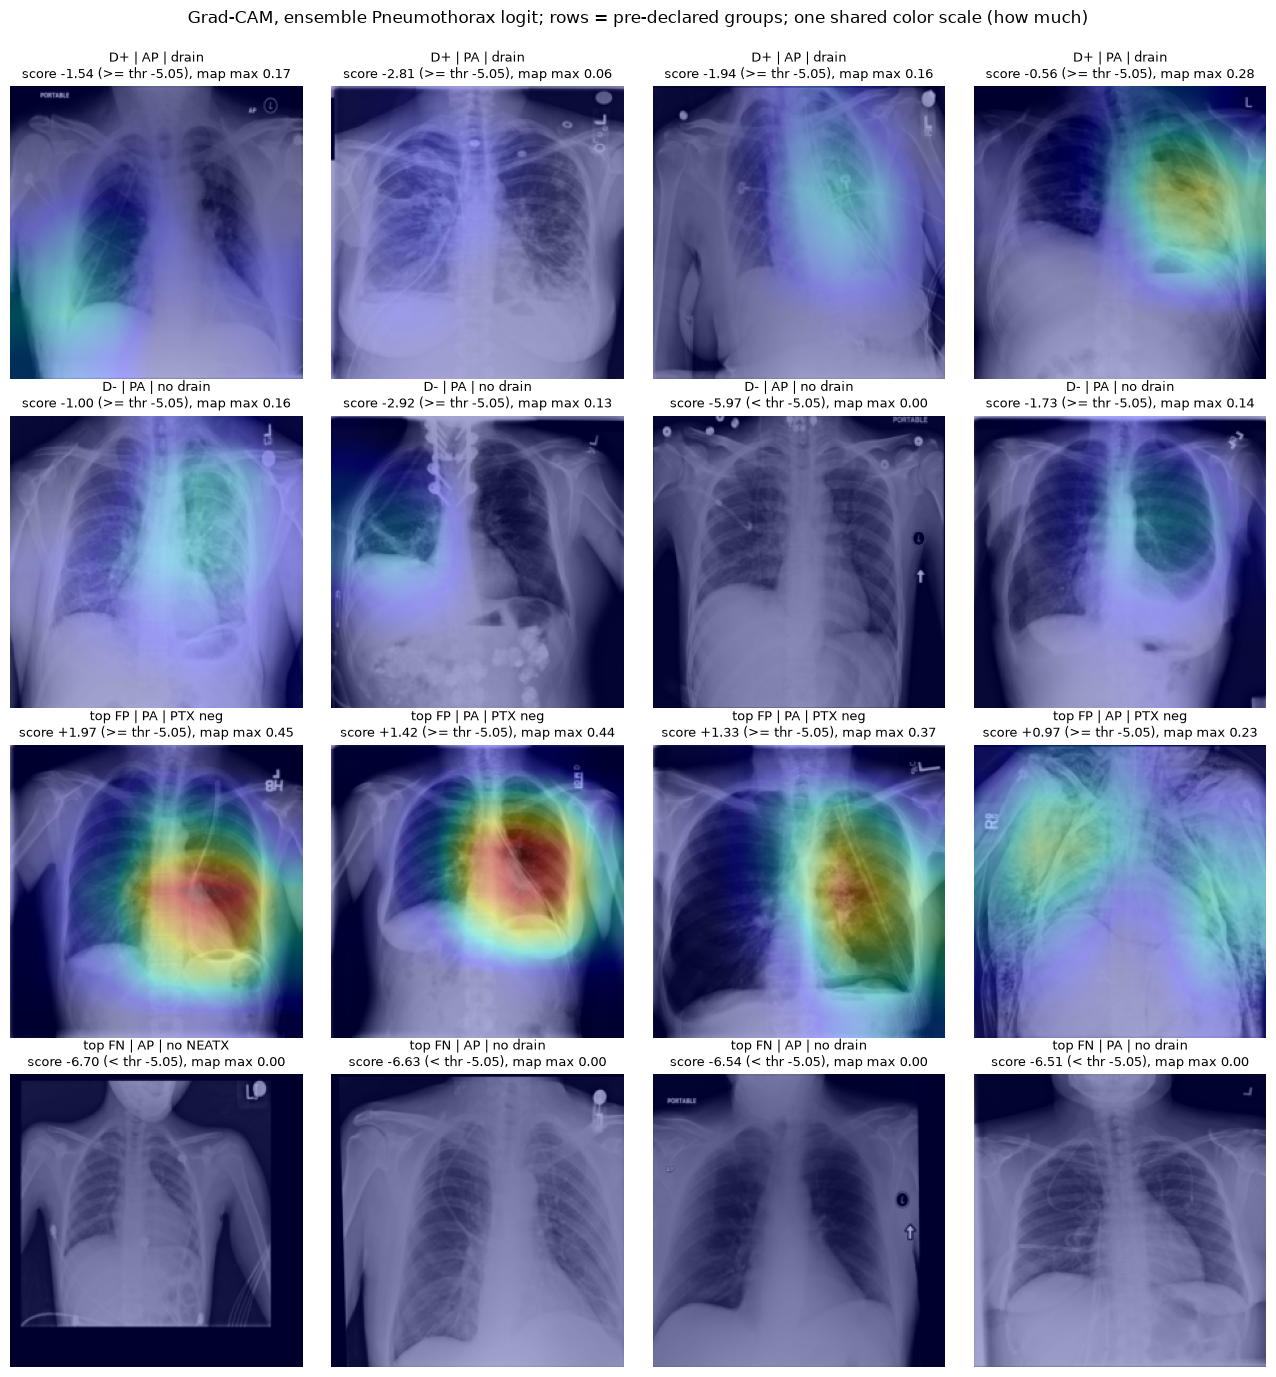

In [11]:
img = (x.float().cpu() * torch.tensor(IMAGENET_STD)[:, None, None] + torch.tensor(IMAGENET_MEAN)[:, None, None])[:, 0].numpy()


def plot_grid(per_image_scale: bool) -> None:
    fig, axes = plt.subplots(4, 4, figsize=(13, 14))
    for k, ax in enumerate(axes.flat):
        i = sel_rows[k]
        vmax = max(heat[k].max(), 0.01 * heat.max()) if per_image_scale else heat.max()  # floor: an all-zero map stays blank
        ax.imshow(img[k], cmap="gray")
        ax.imshow(heat[k], cmap="jet", alpha=0.35, vmin=0, vmax=vmax)
        tag = {1.0: "drain", 0.0: "no drain"}.get(drain[i], "no NEATX") if y[i] else "PTX neg"
        ax.set_title(f"{sel_group[k]} | {val_df.loc[i, 'View Position']} | {tag}\nscore {s[i]:+.2f} ({'>=' if hit[i] else '<'} thr {thr[PTX]:.2f}), map max {heat[k].max():.2f}", fontsize=9)
        ax.axis("off")
    scale = "each map scaled to its own max (where)" if per_image_scale else "one shared color scale (how much)"
    fig.suptitle(f"Grad-CAM, ensemble Pneumothorax logit; rows = pre-declared groups; {scale}")
    plt.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()


plot_grid(per_image_scale=False)

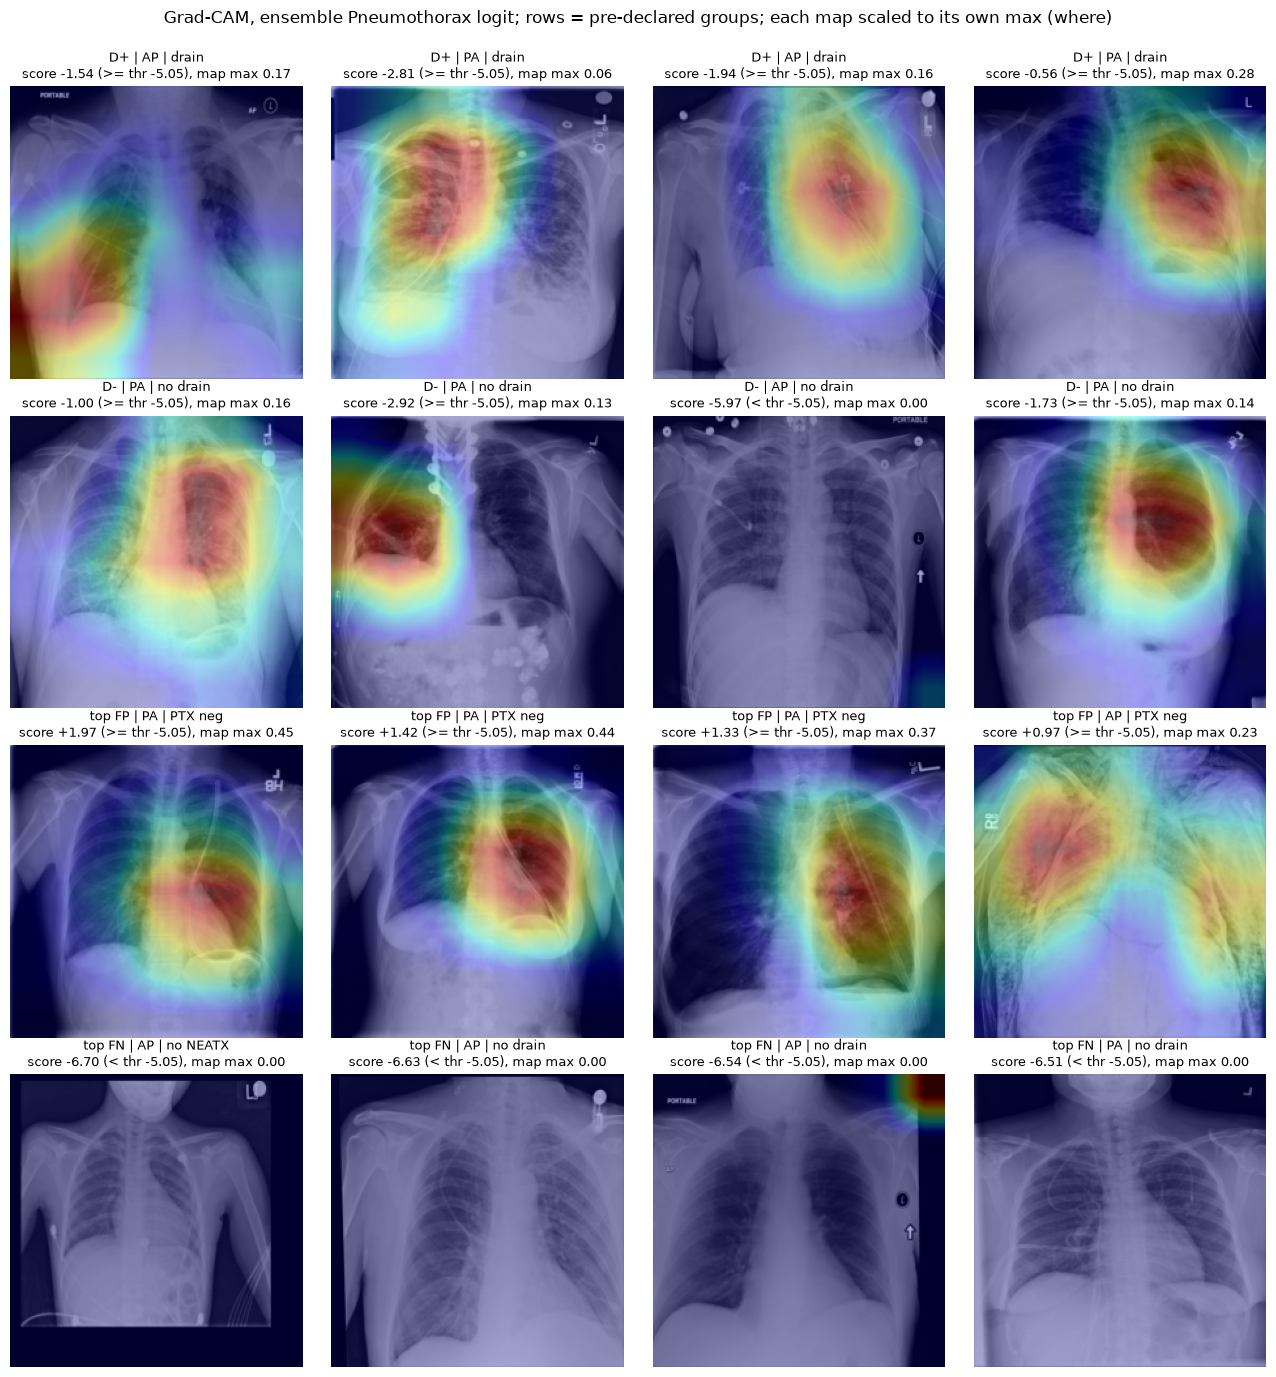

In [12]:
plot_grid(per_image_scale=True)

## Drains, errors, Grad-CAM: results (val, exploratory)
- Definitions were pre-declared and pushed before anything was computed (commit `98f2d7c`). Nothing here changes the model, the score or the thresholds.
- Score: the frozen primary score (mean of member logits), rebuilt from hash-verified val logits; the frozen thresholds reproduce val sensitivity 0.9001-0.9091.
- NEATX on dev: train 1,564 of 2,340 Pneumothorax positives annotated, 33.6% with a drain (descriptive only). Val: D+ 91 images / 35 patients, D- 128 / 77, unannotated 78 / 45, N 10,245 / 3,488.
- **A1 (exploratory):** AUROC D+ vs N 0.949 [0.924, 0.966], D- vs N 0.817 [0.768, 0.859]; difference +0.131 [+0.086, +0.181], so the pre-declared H1 criterion is met on val. Sensitivity at the frozen threshold: D+ 0.989, D- 0.844, difference +0.145 [+0.072, +0.226]. Overall Pneumothorax AUROC 0.864 [0.832, 0.891]. Caveats: 35 D+ patients, non-expert drain labels, unknown drain status of N, and drained pneumothoraces may be larger (easier) regardless of the tube. Test is confirmatory.
- Secondary: on D-, ensemble minus s0 +0.0038 [-0.0058, +0.0139], minus s1 +0.0092 [-0.0007, +0.0190]; no clear ensemble gain on the hard cases on val.
- AP share (descriptive): D+ 0.35, D- 0.24, unannotated 0.39, N 0.32.
- **A2:** macro13 sensitivity AP minus PA +0.012 [-0.031, +0.056] (no clear difference); first study minus follow-up -0.061 [-0.100, -0.027] (first studies are missed more often). Per-class subgroup rates on small counts swing widely (e.g. Edema PA 0.53 on 15 positives).
- **A3:** for this architecture (global average pool + linear head) Grad-CAM equals CAM; the 7x7 map sums to logit minus bias (checked, < 1e-6). The most confident false negatives have (near-)zero maps (max < 0.005; any hot spot on the per-image scale is a stretched near-zero map); the most confident false positives have the strongest maps. Maps are lung-field-level blobs; qualitative only, no localization claim.
- Reproducibility: re-running the hash-verified checkpoints (bf16 autocast, cudnn.benchmark) does not bit-reproduce the saved logits: about 1e-2 on these 16 images; on all of val (scratch) up to 0.02-0.035, varying run to run, macro13 unchanged to 1e-4, and 76-134 of 147,588 threshold decisions flip (some classes' val sensitivity dips to 0.896). The test entry point's reproduction check therefore needs stated tolerances; deterministic inference should be considered.